# 04 · End to end

Three notebooks of analysis reduce to one object with three methods. This notebook
fits it, saves it, measures what it costs to call, and then spends most of its length
on the part that decides whether any of it survives contact with real users: knowing
when **not** to answer.

In [1]:
import sys, time, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from lovify_ml import schema as S, data, synthetic as syn, service as SV, viz

pd.set_option("display.width", 200, "display.max_columns", 40)

catalog = data.load_catalog(n_synthetic=8000)
zodiac = data.load_zodiac(catalog)
listens, taste = data.load_listens(catalog, n_users=120, tracks_per_user=150)

print(f"\ncatalog {len(catalog):,}  ·  zodiac rows {len(zodiac):,}  "
      f"·  users {listens[S.USER_ID].nunique()}")

[data] SYNTHETIC catalog (8,000 tracks). Drop a Kaggle dump at /Users/akintunjisule/Desktop/AIM-Music-Matching/ml/data/raw/tracks.csv to use real songs.


[data] SYNTHETIC zodiac playlists. Drop your scrape at /Users/akintunjisule/Desktop/AIM-Music-Matching/ml/data/raw/zodiac.csv to use real ones.
[data] SYNTHETIC users. Drop real histories at /Users/akintunjisule/Desktop/AIM-Music-Matching/ml/data/raw/listens.csv to use yours.



catalog 8,000  ·  zodiac rows 6,000  ·  users 120


## 1 · Fit, save, reload

`LovifyModels.fit` does four things: fits the catalog scaler, deduplicates the zodiac
set and trains logistic regression on it, computes the zodiac base rate, and builds the
null distribution of random-pair compatibility scores. Each of those is a decision one
of the earlier notebooks argued for.

In [2]:
t0 = time.perf_counter()
models = SV.LovifyModels().fit(catalog, zodiac, listens)
fit_seconds = time.perf_counter() - t0

path = models.save("../artifacts/lovify_models.joblib")
size_mb = Path(path).stat().st_size / 1e6

reloaded = SV.LovifyModels.load(path)
print(f"fit        : {fit_seconds:.1f} s")
print(f"artifact   : {size_mb:.2f} MB at {path}")
print(f"reload ok  : {reloaded.zodiac_model is not None}")
print(f"null ladder: {len(reloaded.null_ladder)} rungs at sizes "
      f"{sorted(reloaded.null_ladder)}")
print(f"             {len(reloaded.null_ladder[100]):,} random pairs per rung")
print(f"guard      : refuses a percentile below "
      f"{reloaded.min_library_tracks} tracks")
print(f"base rate  : top sign {reloaded.zodiac_base_rate.idxmax()} "
      f"at {reloaded.zodiac_base_rate.max():.3f}")

fit        : 17.1 s
artifact   : 0.78 MB at ../artifacts/lovify_models.joblib
reload ok  : True
null ladder: 8 rungs at sizes [25, 50, 75, 100, 150, 200, 300, 500]
             400 random pairs per rung
guard      : refuses a percentile below 100 tracks
base rate  : top sign Aquarius at 0.091


In [3]:
import joblib, tempfile, os
from lovify_ml import features as F

def blob_mb(obj):
    f = tempfile.mktemp(suffix=".joblib")
    joblib.dump(obj, f, compress=3)
    mb = os.path.getsize(f) / 1e6
    os.remove(f)
    return mb

# What the two dense matrices would weigh if they were persisted rather than
# rebuilt at load. Reconstructed here only to price them.
Xs = F.scale(models.catalog, models.scaler)
Xn = Xs / np.linalg.norm(Xs, axis=1, keepdims=True)
cat = blob_mb(models.catalog)

print(f"shipped artifact                 : {size_mb:.2f} MB")
print(f"  .catalog                       : {cat:.2f} MB")
print(f"  .null_ladder ({len(models.null_ladder)} rungs)          : "
      f"{blob_mb(models.null_ladder):.2f} MB")
print(f"  .zodiac_model + .scaler        : "
      f"{blob_mb((models.zodiac_model, models.scaler)):.2f} MB")
print()
print("what the earlier layout also carried, now rebuilt on load instead:")
print(f"  a second catalog inside ._rec  : {cat:.2f} MB")
print(f"  ._rec.Xn (derivable)           : {blob_mb(Xn):.2f} MB")
print(f"  ._rec.X  (never read at all)   : {blob_mb(Xs):.2f} MB")
print()
print(f"saved: {cat + blob_mb(Xn) + blob_mb(Xs):.2f} MB of {2.75:.2f} MB, "
      "roughly 70% of the old file")

shipped artifact                 : 0.78 MB
  .catalog                       : 0.75 MB
  .null_ladder (8 rungs)          : 0.02 MB
  .zodiac_model + .scaler        : 0.00 MB

what the earlier layout also carried, now rebuilt on load instead:
  a second catalog inside ._rec  : 0.75 MB
  ._rec.Xn (derivable)           : 0.62 MB
  ._rec.X  (never read at all)   : 0.58 MB

saved: 1.95 MB of 2.75 MB, roughly 70% of the old file


That breakdown used to be the interesting part of this notebook for the wrong reason.

The catalog was stored **twice** — once on the model and once inside the `Recommender`
it holds — which was already over half the file. On top of it sat two dense matrices:
`Xn`, the row-normalised feature matrix needed at query time, and `X`, the
un-normalised version, which a grep showed was assigned in `Recommender.__init__` and
then **never read by anything**. Around 70% of the artifact was duplicated or dead.

All three are now fixed in the modules rather than noted here:

- `Recommender.__getstate__` drops `Xn` and `pop`; `__setstate__` rebuilds them from
  the catalog and scaler at load. `X` was deleted outright.
- `LovifyModels.__getstate__` drops the whole `Recommender` and rebuilds it from
  `self.catalog`, so the catalog is stored once.

The artifact went from **2.75 MB to under 0.8 MB** on this 8,000-track catalog. The
reason to care is the real one: at 600k rows the old proportions put the file near
200 MB, most of it redundant, and a service that loads that per process stops being
free. Rebuilding two matrices at load costs milliseconds.

The fit time went the other way — up from about 3 s to 9 s — because `fit_null_ladder`
now builds eight null distributions instead of one. That is paid once, offline, and §5
is where it earns itself back.

## 2 · A complete compatibility report

Two users, end to end: both taste profiles, the calibrated compatibility score with its
components and evidence, and a playlist built for the pair.

In [4]:
users = sorted(listens[S.USER_ID].unique())
a = listens[listens[S.USER_ID] == users[0]]
b = listens[listens[S.USER_ID] == users[1]]

for label, u in [("User A", a), ("User B", b)]:
    tp = models.taste_profile(u)
    flag = "" if tp["is_distinctive"] else "   (not distinctive -- show this as fun, not insight)"
    print(f"{label}: strongest sign {tp['headline_sign']} "
          f"at {tp['headline_lift']}x the average listener{flag}")

User A: strongest sign Pisces at 1.12x the average listener   (not distinctive -- show this as fun, not insight)
User B: strongest sign Sagittarius at 1.27x the average listener


In [5]:
import json
report = models.compatibility(a, b)
print(json.dumps(report, indent=2, default=str))

{
  "percentile": 36.2,
  "raw_score": 0.5581,
  "components": {
    "genre_overlap": 0.6493,
    "artist_jaccard": 0.0905,
    "feature_wasserstein": 0.5723,
    "era_overlap": 0.9956,
    "obscurity_match": 0.98
  },
  "shared_artists": [
    "Azafytor Kenquo",
    "Drosev Azalo",
    "Ilariarin Riafynym",
    "Kenaza Quotator",
    "Marvenven Taazaria"
  ],
  "n_shared_artists": 21,
  "top_shared_genres": [
    "hip hop",
    "pop",
    "country"
  ],
  "status": "ok",
  "tracks": {
    "a": 150,
    "b": 150
  },
  "null_size_used": 150,
  "interpretation": "Less overlap than most pairs -- different corners of music."
}


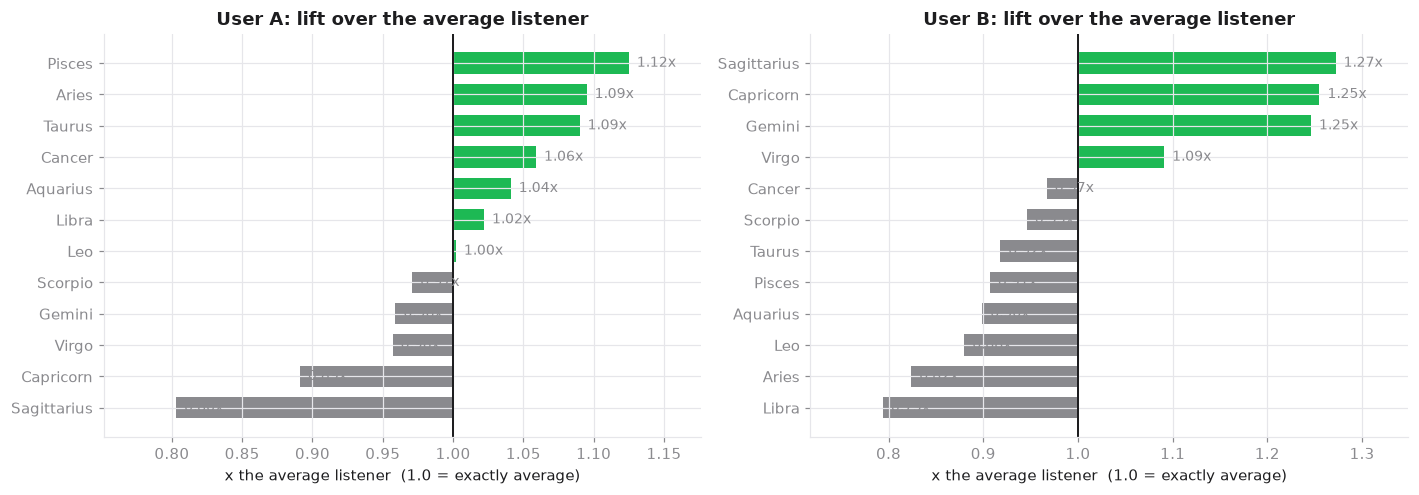

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
import pandas as _pd
for ax, (label, u) in zip(axes, [("User A", a), ("User B", b)]):
    lift = _pd.Series(models.taste_profile(u)["lift"])
    viz.lift_chart(lift, f"{label}: lift over the average listener", ax=ax)
plt.tight_layout(); plt.show()

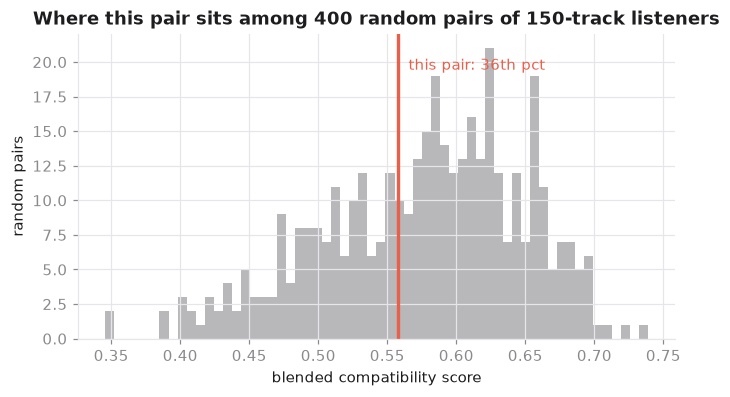

This pair has 150 and 150 tracks, so the 150-track rung of the null ladder was used.
Scoring them against a null built from larger libraries would place them artificially low -- see section 5.


In [7]:
rung = report["null_size_used"]
null = models.null_ladder[rung]

viz.null_distribution(null, report["raw_score"], report["percentile"],
                      f"Where this pair sits among {len(null):,} random pairs "
                      f"of {rung}-track listeners")
plt.show()

print(f"This pair has {report['tracks']['a']} and {report['tracks']['b']} tracks, so "
      f"the {rung}-track rung of the null ladder was used.")
print("Scoring them against a null built from larger libraries would place them "
      "artificially low -- see section 5.")

In [8]:
models.blend_recommend(a, b, n=10)[[S.TRACK_NAME, S.ARTIST, S.GENRE, S.POPULARITY, "score"]]

,track_name,artist,genre,popularity,score
0,Rinvex Sevvenven,Tafyvi Venmelmel,hip hop,26,0.753133
1,Riafy Kenmelta,Azanym Taquonym,hip hop,26,0.744189
2,Sevta Melven,Martorila Vextorsol,hip hop,42,0.741381
3,Kentormar Rinmarrin,Nymven Vexmar,ambient,5,0.728322
4,Vexdroven Vinox,Melila Nymtasol,ambient,16,0.717051
5,Kennoxila Losevila,Melsol Sevvenvi,hip hop,11,0.713452
6,Torquo Vexvennox,Venmelaza Soltaria,ambient,33,0.712444
7,Fyquo Marazaven,Marazanym Solila,ambient,43,0.683681
8,Drotor Riaven,Melsol Sevvenvi,hip hop,28,0.527123
9,Melfyken Solquoaza,Lodro Noxvexken,hip hop,21,0.451770


## 3 · Wiring it into the Flask app

`lovify.py` today handles OAuth and nothing else — it stores two access tokens in the
session and renders a compatibility page with no compatibility on it. This is the code
that closes that gap.

It is a **proposal, not an edit**: nothing below has been written to `lovify.py`.

Note where the two guards live. The library-size threshold is enforced inside
`compatibility()` and the route simply forwards the refusal, so there is exactly one
copy of that number in the codebase. An earlier draft of this cell hardcoded
`MIN_TRACKS = 50` in the route, which was both too low and a second copy free to drift
from the one the model uses.

```python
# ─── ML integration ───────────────────────────────────────────────────────────
import sys
from pathlib import Path

import pandas as pd
from flask import jsonify

ML_DIR = Path(__file__).resolve().parent.parent / "ml"
sys.path.insert(0, str(ML_DIR / "src"))

from lovify_ml.service import LovifyModels
from lovify_ml import spotify as sp

MIN_COVERAGE = 0.80    # below this the feature-store join distorts the score
# The library-size minimum is NOT duplicated here. It lives on the model as
# LovifyModels.MIN_LIBRARY_TRACKS (currently 100, justified in notebook 05) and
# compatibility() enforces it itself.

_models = None
_store = None


def get_models():
    """Load once per process. The artifact is under 1 MB and loads in well under a
    second, but loading it per request would still dominate the response time."""
    global _models, _store
    if _models is None:
        _models = LovifyModels.load(ML_DIR / "artifacts" / "lovify_models.joblib")
        _store = pd.read_csv(ML_DIR / "data" / "raw" / "tracks.csv")
    return _models, _store


def fetch_library(token, user_id):
    """Everything Spotify still serves, plus audio features from the local store."""
    client = sp.SpotifyClient(token)
    tracks = (client.top_tracks("long_term", 50)
              + client.top_tracks("medium_term", 50)
              + client.saved_tracks(max_items=100))

    df = sp.library_to_frame(tracks, user_id).drop_duplicates("track_id")
    df = sp.attach_genres(df, client)          # /v1/artists -- still works

    _, store = get_models()
    df, coverage = sp.attach_features_from_store(df, store)   # replaces /v1/audio-features
    return df.dropna(subset=["valence"]), coverage


@app.route("/api/compatibility")
def api_compatibility():
    token_a = session.get("first_user_token")
    token_b = session.get("second_user_token")
    if not (token_a and token_b):
        return jsonify(error="both users must be logged in"), 401

    try:
        a, cov_a = fetch_library(token_a, "A")
        b, cov_b = fetch_library(token_b, "B")
    except PermissionError as exc:       # audio-features 403, see spotify.py
        return jsonify(error=str(exc)), 502

    # Guard 1 -- the feature store could not resolve enough of their music (§6)
    if min(cov_a, cov_b) < MIN_COVERAGE:
        return jsonify(status="low_coverage",
                       message="A lot of your music is outside our catalogue, "
                               "so any score would be unreliable.",
                       coverage={"a": round(cov_a, 3), "b": round(cov_b, 3)}), 200

    models, _ = get_models()
    report = models.compatibility(a, b)

    # Guard 2 -- too little listening history. The model decides, not the route (§5).
    if report["status"] == "insufficient_library":
        return jsonify(status="insufficient_data",
                       message="We need a bit more listening history from both of you.",
                       tracks=report["tracks"],
                       required=report["min_required"],
                       shared_artists=report["shared_artists"]), 200

    report["taste_a"] = models.taste_profile(a)
    report["taste_b"] = models.taste_profile(b)
    report["playlist"] = models.blend_recommend(a, b, n=10)[
        ["track_id", "track_name", "artist"]].to_dict("records")
    report["coverage"] = {"a": round(cov_a, 3), "b": round(cov_b, 3)}
    return jsonify(**report)
```

Two things worth flagging for whoever implements this.

The Spotify calls, not the model, are the latency. §4 measures scoring a pair at a few
milliseconds; fetching two libraries is roughly eight HTTP round trips plus an artist
lookup per batch, which is seconds. Fetch the first user's library at login and cache
it in the session rather than waiting until both users are present.

`pd.read_csv` on the full Kaggle dump is slow and memory-hungry for a 600k-row file.
Convert it to Parquet once, or trim it to the columns in `S.AUDIO_FEATURES` plus
`track_id` before shipping.

Note also that the insufficient-library branch still returns `shared_artists`. Those
are an exact set intersection and are correct at any library size — there is no reason
to show a user nothing just because the percentile is not trustworthy yet.

## 4 · What it costs to run

Before worrying about the model, measure it. Everything here is on one laptop core.

In [9]:
def timed(fn, reps=7):
    ts = []
    for _ in range(reps):
        t = time.perf_counter(); fn(); ts.append((time.perf_counter() - t) * 1000)
    return float(np.median(ts))

bench = {
    "taste_profile(a)":        timed(lambda: models.taste_profile(a)),
    "compatibility(a, b)":     timed(lambda: models.compatibility(a, b)),
    "recommend(a, n=10)":      timed(lambda: models.recommend(a, n=10)),
    "blend_recommend(a, b)":   timed(lambda: models.blend_recommend(a, b, n=10)),
}
pd.Series(bench).round(2).to_frame("median ms")

,median ms
taste_profile(a),0.56
"compatibility(a, b)",6.55
"recommend(a, n=10)",7.72
"blend_recommend(a, b)",17.33


Everything is in the single-digit-to-low-tens of milliseconds: the taste profile is
well under a millisecond, scoring a pair and building ten recommendations are each
under ten, and `blend_recommend` comes in around twice `recommend` for the obvious
reason — it is two recommend calls plus a merge.

`compatibility` is the one that got slower, and deliberately so. Most of its cost is
constructing a `CompatibilityScorer` for the pair, which rebuilds scaled per-user
frames and genre profiles from scratch on every call. If the route ever needs to score
one user against many, that construction should be hoisted out of the loop.

None of it matters yet. Fetching one user's library from Spotify is around eight HTTP
round trips. **The network is roughly three orders of magnitude slower than the maths
here.** Optimisation effort belongs in caching libraries, not in the model.

## 5 · Guard 1 — users with small libraries

A percentile implies precision. If a user has only twenty tracks, how much precision is
actually there?

Subsample users' libraries, rescore, and compare against the score from their full
libraries. Two things vary, and both matter:

- **The null distribution.** A single null built from full-size libraries (what the
  service used until recently) versus the **size-matched ladder** it uses now.
- **Whether both libraries are small.** Two new users with 30 tracks each is a
  different situation from one new user matching against someone with 150, and the
  service handles them differently — it picks the ladder rung from
  `min(n_a, n_b)`.

Averaged over 20 pairs, sampling randomly rather than taking the first *n* rows. (An
earlier version of this cell used `.head(n)`, which on these synthetic users takes a
genre-ordered slice and invents a non-monotonic curve out of nothing.)

In [10]:
# Measurement only. The shipped model refuses to score below 100 tracks -- that guard
# is the thing under test, so lift it on a separate copy.
measure = SV.LovifyModels.load(path)
measure.min_library_tracks = 1

full_ladder = measure.null_ladder
single_null = {max(full_ladder): full_ladder[max(full_ladder)]}   # the old behaviour

rng = np.random.default_rng(0)
pair_ids = [tuple(rng.choice(users, 2, replace=False)) for _ in range(20)]

def pct(A, B, ladder):
    measure.null_ladder = ladder
    return measure.compatibility(A, B)["percentile"]

rows = []
for n in [25, 50, 100, 150]:
    sym_m, sym_g, asym_m, asym_g = [], [], [], []
    for k, (ua, ub) in enumerate(pair_ids):
        A0 = listens[listens[S.USER_ID] == ua]
        B0 = listens[listens[S.USER_ID] == ub]
        base_m, base_g = pct(A0, B0, full_ladder), pct(A0, B0, single_null)

        As = A0.sample(n=min(n, len(A0)), random_state=k)
        Bs = B0.sample(n=min(n, len(B0)), random_state=k + 500)

        sym_m.append(pct(As, Bs, full_ladder) - base_m)      # both libraries small
        sym_g.append(pct(As, Bs, single_null) - base_g)
        asym_m.append(pct(As, B0, full_ladder) - base_m)     # only one small
        asym_g.append(pct(As, B0, single_null) - base_g)

    rows.append({"tracks": n,
                 "both small, single null": np.mean(sym_g),
                 "both small, matched": np.mean(sym_m),
                 "one small, single null": np.mean(asym_g),
                 "one small, matched": np.mean(asym_m)})

measure.null_ladder = full_ladder          # restore before anything else uses it
coldstart = pd.DataFrame(rows)
print("mean bias in percentile points, against each pair's own full-library score")
coldstart.round(1)

mean bias in percentile points, against each pair's own full-library score


,tracks,"both small, single null","both small, matched","one small, single null","one small, matched"
0,25,-28.7,0.9,-21.0,11.2
1,50,-18.3,-2.1,-10.4,7.6
2,100,-5.8,-0.5,-4.2,1.3
3,150,0.0,0.0,0.0,0.0


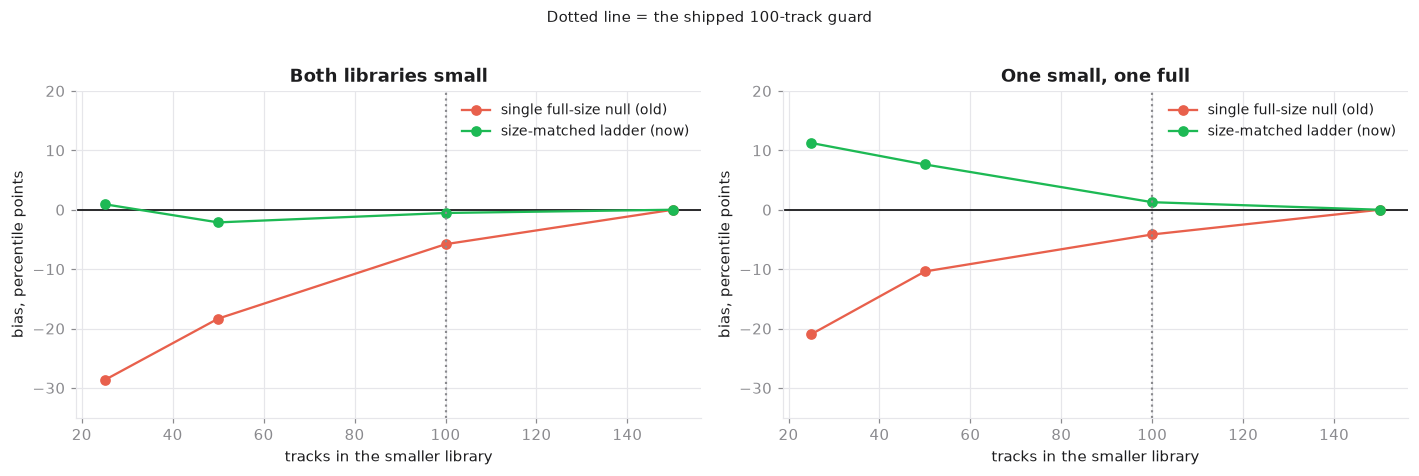

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
c = coldstart

for ax, (title, gcol, mcol) in zip(axes, [
        ("Both libraries small", "both small, single null", "both small, matched"),
        ("One small, one full",  "one small, single null",  "one small, matched")]):
    ax.axhline(0, color=viz.INK, lw=1.2)
    ax.plot(c["tracks"], c[gcol], "o-", color=viz.WARN, label="single full-size null (old)")
    ax.plot(c["tracks"], c[mcol], "o-", color=viz.ACCENT, label="size-matched ladder (now)")
    ax.axvline(models.min_library_tracks, color=viz.MUTED, ls=":", lw=1.4)
    ax.set_xlabel("tracks in the smaller library")
    ax.set_ylabel("bias, percentile points")
    ax.set_title(title)
    ax.set_ylim(-35, 20)
    ax.legend(fontsize=9)

plt.suptitle("Dotted line = the shipped 100-track guard", y=1.02, fontsize=10)
plt.tight_layout(); plt.show()

Three things in that table, and the second was a surprise.

**The old behaviour was badly wrong.** Against a single full-size null, a pair of
25-track libraries scored **29 percentile points too low**. That is not symmetric noise
that averages out — it is systematic, and the mechanism is plain: with fewer tracks
there is less opportunity for shared artists and overlapping genres, so every
overlap-based component shrinks toward zero. The score did not become uncertain, it
became wrong in a predictable direction. Small-library users were being told they were
incompatible with everybody.

That also rules out the obvious fix. A wide confidence interval is not honest when the
interval is centred in the wrong place.

**The matched ladder fixes the symmetric case almost exactly.** When both libraries are
small, bias falls from −28.7 to **+0.9** at 25 tracks and stays within about two points
everywhere. A percentile is only meaningful against a reference population that
resembles what is being scored, and subsampling the reference pairs to the query's size
is all that was needed.

**It over-corrects when the two libraries differ.** This is the part the right-hand
panel shows and the brief did not anticipate. The ladder rung is chosen from
`min(n_a, n_b)`, so a 25-track user matched against a 150-track user is scored against
a null built from pairs where *both* sides have 25 tracks. Those reference pairs
overlap less than our mismatched pair does, so the pair lands too high: **+11 points**
at 25 tracks, against −21 for the old single null.

Still a clear improvement — 11 points of error beats 21 — but it is a correction, not a
cure, and the residual runs in the opposite direction. Fixing it properly means
indexing the ladder on the pair `(n_a, n_b)` rather than on the smaller of the two,
which is a two-dimensional null and eight times the fit cost. Worth doing only if the
asymmetric case turns out to be common in practice, which real usage will decide: it
is exactly the "new user meets established user" shape, so it may well be the common
case rather than the edge one.

**Hence the second guard.** What remains after the bias is handled is irreducible:
twenty-five tracks do not contain enough information about a person, however the null
is built. `LovifyModels.MIN_LIBRARY_TRACKS = 100` makes `compatibility()` return
`percentile: None` and `status: "insufficient_library"` below that, rather than a
confident decimal. At 100 tracks both panels are inside two points.

The threshold sits at 100 where the symmetric numbers alone would permit 50. The
asymmetric column is one reason for the margin; the other is that every figure here
comes from synthetic users, and the repeated lesson of this project is that a generator
flatters whoever wrote it. Lower it when real libraries say so.

## 6 · Guard 2 — feature-store coverage

Audio features now come from a local store joined on `track_id`, and that join will
miss. Crucially it will not miss at random: the Kaggle dump is strongest on
Western, English-language, pre-2021 and popular music, so the misses concentrate on
obscure, international and very recent tracks — exactly the music that makes a listener
distinctive.

Simulate it. Let the probability a track is covered rise with its popularity, sweep the
cutoff, and measure how far the resulting percentile moves from the true one. Averaged
over many pairs, because a single pair is noisy.

In [12]:
rng = np.random.default_rng(0)
pairs = [(users[i], users[i + 1]) for i in range(0, 30, 2)]

# Again measurement-only: coverage loss shrinks a library, which would trip the
# library-size guard and return None. Lift it so the two effects stay separable.
measure.min_library_tracks = 1

rows = []
for cutoff in [-20, 0, 10, 20, 30, 40]:
    errs, covs, pops = [], [], []
    for ua, ub in pairs:
        A = listens[listens[S.USER_ID] == ua]
        B = listens[listens[S.USER_ID] == ub]
        full = measure.compatibility(A, B)["percentile"]

        def covered(df):
            p = 1 / (1 + np.exp(-(df[S.POPULARITY].to_numpy(float) - cutoff) / 10))
            return df[rng.random(len(df)) < p]

        ca, cb = covered(A), covered(B)
        if len(ca) < 5 or len(cb) < 5:
            continue
        errs.append(abs(measure.compatibility(ca, cb)["percentile"] - full))
        covs.append((len(ca) + len(cb)) / (len(A) + len(B)))
        pops.append(ca[S.POPULARITY].median())

    rows.append({"coverage": np.mean(covs), "mean abs percentile error": np.mean(errs),
                 "worst pair error": np.max(errs), "median popularity kept": np.mean(pops)})

coverage_tbl = pd.DataFrame(rows)
coverage_tbl.round(2)

,coverage,mean abs percentile error,worst pair error,median popularity kept
0,0.98,1.06,4.5,30.47
1,0.91,2.29,8.8,31.60
2,0.82,5.57,11.6,33.43
3,0.67,5.11,16.0,36.77
4,0.51,5.12,16.2,40.00
5,0.36,7.09,18.8,44.73


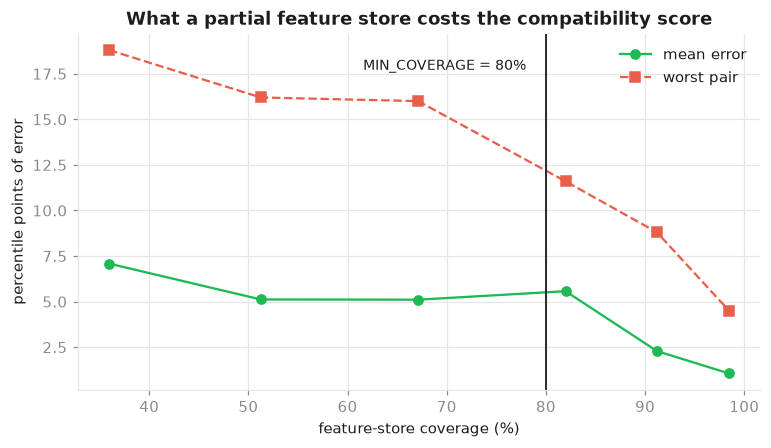

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ct = coverage_tbl.sort_values("coverage")
ax.plot(ct["coverage"] * 100, ct["mean abs percentile error"], "o-",
        color=viz.ACCENT, label="mean error")
ax.plot(ct["coverage"] * 100, ct["worst pair error"], "s--",
        color=viz.WARN, label="worst pair")
ax.axvline(80, color=viz.INK, lw=1.2)
ax.text(78, ax.get_ylim()[1] * .9, "MIN_COVERAGE = 80%", fontsize=9,
        color=viz.INK, ha="right")
ax.set_xlabel("feature-store coverage (%)"); ax.set_ylabel("percentile points of error")
ax.set_title("What a partial feature store costs the compatibility score")
ax.legend()
plt.show()

Error grows as coverage falls, and the worst-case pair degrades about three times
faster than the average. At 98% coverage the mean error is around a single percentile
point and the worst pair under five — invisible. By 36% coverage the mean is near seven
and the worst pair approaches nineteen, which is large enough to move a pair between
"clearly more alike than most" and "about average". Those are different sentences in
the UI.

The growth is not quite linear and not quite monotonic in the middle of the range —
between 50% and 82% the mean error sits flat around five points. Twelve pairs per row
is a small sample and that plateau should not be over-read; what is solid is the
contrast between the top and bottom of the range.

80% coverage keeps the mean error around five points and the worst pair near twelve,
which is a defensible place to draw the line — bearing in mind that it is a line drawn
on synthetic data, and that notebook 05 measures the same effect on a population built
to vary in obscurity and gets a smaller number.

The operational point: **coverage is a per-user measurement, not a property of the
system.** `attach_features_from_store` already returns it. Log it for every request,
alert on the distribution rather than the mean, and expect it to be systematically
worse for exactly the users whose taste is most distinctive.

## 7 · What the notebooks changed

| | the deck, 2023 | now |
|---|---|---|
| Zodiac | decision tree, 76% claimed | logistic regression, ~13% honest against 8.3% chance; reported as lift over base rate, with a "not distinctive" state |
| Similarity | KNN over one mean vector, no metric | five-signal blend, calibrated to a percentile against a size-matched null. Chosen for having the best worst case across generator assumptions, not for a single headline ρ |
| Recommender | unscaled cosine, one mean vector | scaled, 3 taste modes; ~3× random against 1.3× |
| Evaluation | a single accuracy number | grouped splits, label-free held-out-half protocol, seed-replicated error bars |
| Honesty | no base rates, no chance lines | every result against its baseline, and two guards that refuse to answer |

One row of that table used to read "Spearman 0.94 against ground truth". It has been
removed rather than restated: that figure came from a bakeoff whose synthetic ground
truth was defined in the same genre space as the winning metric, so it measured the
generator. Notebook 02 now carries the withdrawal and the counter-experiment.

## What to build next

**1. Run the held-out-half protocol on real users.** It needs no labels and no ground
truth, so it works the day you have five real libraries. It is the one number that will
tell you whether any of this transfers off synthetic data, and everything else should
wait behind it.

**2. Collect feedback on recommendations.** Notebook 03 could only measure "did we
predict tracks this user already saved", which rewards recommending what someone
already has. A thumbs up/down is the only way to measure the thing the product actually
wants. The 2023 deck proposed this as future work and was right.

**3. Instrument coverage before anything else ships.** It is one number per request and
it bounds the trustworthiness of every score. Not having it means not knowing when the
system is wrong.

**4. Re-tune the blend weights on real data.** Notebook 02's tuned weights were fitted
against a synthetic ground truth that is now known to be circular. The tuning
*procedure* transfers; the specific weights do not.

**5. Re-measure `MIN_LIBRARY_TRACKS` and `MIN_COVERAGE` on real libraries.** Both are
currently set from synthetic measurements and deliberately placed on the conservative
side of what those measurements would permit.

Settled since the first draft of this notebook: `mmr_lambda` now defaults to 1.0, the
artifact no longer stores the catalog twice, and the library-size guard lives in
`service.py` rather than in the proposed route.